# Beyond Accuracy — RQ2 verified results and risk–coverage analysis

Run **Kernel → Restart & Run All**. The notebook reads five ZIP archives from `C:\Research` and saves a high quality SVG/PDF/PNG figure, two LaTeX tables, and separate Results, Discussion, and Methods fragments in `C:\Research\Beyond_Accuracy_Reproduction\RQ2_Notebook_Output`.

The Climate archive and the **archived aligned Yelp cohort** are checked condition by condition against their saved Accuracy, Macro-F1, and 10-bin ECE. All models use matched evaluation examples within each setting/period/seed. Frozen-model comparisons use canonical P3. Yelp P3 rows with an abstain flag and a valid label are scored using that label, matching the canonical run.

Confidence-based selective risk is a **derived analysis of saved P3 predictions**. The 80% result and exploratory 20–100% curve use fractional inclusion of tied scores, representing the expected error under uniform random tie-breaking; P5 explicit abstention is separate. The program only reads archived predictions and never fits or invokes a model.

**Requirements:** Python with `numpy`, `matplotlib`, and Jupyter. Edit only the paths in the next cell if your files are elsewhere. The resulting prose files are reviewable manuscript drafts; inspect their claims, labels, references, and journal layout before insertion.


In [6]:
from pathlib import Path
import os
import sys

# Set root to project root (one level up from notebooks/)
ROOT = Path(os.environ.get('BEYOND_ACCURACY_ROOT', str(Path('..').resolve())))
SOURCE_DIR = ROOT / 'archives'
OUT_DIR = ROOT / 'outputs' / 'notebook_output'
sys.path.insert(0, str(ROOT))
print('Project Root:', ROOT)
print('Archives Dir:', SOURCE_DIR)
print('Output Dir:  ', OUT_DIR)


ZIP search: C:\Research
Output: C:\Research\Beyond_Accuracy_Reproduction\RQ2_Notebook_Output


## Verify archives and calculate all reported quantities

This self-contained code recomputes all 180 model–setting–period–seed conditions, checks saved metrics, calculates expected risk for each integer coverage from 20% through 100%, and generates the figure and LaTeX fragments.

In [8]:
"""Self-contained computational core embedded in the RQ2 notebook.

Reads saved predictions only. Produces verified RQ2 tables, SVG figure, and
separate LaTeX Results, Discussion, and Methods fragments. No model fitting.
"""
import csv
import io
import math
import statistics
import zipfile
from collections import Counter, defaultdict
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter


SEEDS = range(42, 47)
PERIODS = ("within", "short", "long")
SETTINGS = ("Climate n500", "Yelp n500", "Yelp n1000")
MODELS = ("distilbert", "tfidf_lr", "phi3.5:latest", "qwen2.5:3b-instruct")
SLUGS = ("distilbert", "tfidf_lr", "phi3.5_latest", "qwen2.5_3b-instruct")
DISPLAY = ("DistilBERT", "TF–IDF+LR", "phi3.5:latest", "qwen2.5:3b-instruct")
TEX_MODELS = ("DistilBERT", "TF--IDF+LR", r"\texttt{phi3.5:latest}",
              r"\texttt{qwen2.5:3b-instruct}")
COLORS = ("#0072B2", "#72777F", "#009E73", "#D55E00")
MARKERS = ("o", "s", "^", "D")
STEMS = dict(climate="completed_prediction_audit",
             frozen="original_yelp_frozen_predictions",
             aligned="yelp_prediction_alignment",
             later="code_and_remaining_results",
             frozen_audit="yelp_results_audit")


def get_csv(z, suffix):
    found = [name for name in z.namelist() if name.replace("\\", "/").endswith(suffix)]
    if len(found) != 1:
        raise ValueError(f"Expected one {suffix} in archive; found {len(found)}")
    with z.open(found[0]) as source:
        return list(csv.DictReader(io.TextIOWrapper(source, encoding="utf-8-sig", newline="")))


def metric_index_climate(z):
    index = {}
    for r in get_csv(z, "metrics_per_condition.csv"):
        if r["dataset"] != "climate" or r["model"] not in MODELS or r["period"] not in PERIODS:
            continue
        expected_prompt = "" if r["model"] in MODELS[:2] else "p3_json_strict"
        if r["prompt_id"] != expected_prompt or int(r["n_per_label"]) != 500:
            continue
        key = ("Climate n500", r["model"], int(r["seed"]), r["period"])
        if key in index:
            raise ValueError(f"Duplicate archived Climate metric: {key}")
        index[key] = r
    return index


def metric_index_yelp(z, models):
    suffix = "later_run/metrics_per_seed.csv" if models == MODELS[:2] else "metrics_frozen_partial.csv"
    index = {}
    for r in get_csv(z, suffix):
        if r["model"] not in models or r["split"] not in PERIODS or r["prompt"] != "p3_json_strict":
            continue
        n = int(r["eval_n_per_label"])
        if n not in (500, 1000):
            continue
        key = (f"Yelp n{n}", r["model"], int(r["seed"]), r["split"])
        if key in index:
            raise ValueError(f"Duplicate archived Yelp metric: {key}")
        index[key] = r
    return index


def ece_10(correct, confidence):
    conf = np.asarray(confidence, dtype=float)
    corr = np.asarray(correct, dtype=float)
    if not np.isfinite(conf).all() or not ((conf >= 0) & (conf <= 1)).all():
        raise ValueError("Confidence missing or outside [0, 1]")
    bounds = np.linspace(0.0, 1.0, 11)
    result = 0.0
    for bin_no in range(10):
        lo, hi = bounds[bin_no], bounds[bin_no+1]
        mask = (conf >= lo) & (conf <= hi if bin_no == 9 else conf < hi)
        if mask.any():
            result += float(mask.mean() * abs(corr[mask].mean() - conf[mask].mean()))
    return result


def macro_f1(rows, labels, gold, pred):
    scores = []
    for lab in labels:
        tp = sum(r[gold] == lab and r[pred] == lab for r in rows)
        fp = sum(r[gold] != lab and r[pred] == lab for r in rows)
        fn = sum(r[gold] == lab and r[pred] != lab for r in rows)
        scores.append(2 * tp / (2 * tp + fp + fn) if 2*tp+fp+fn else 0.0)
    return statistics.mean(scores)


def risk_sweep(scores, errors):
    """Expected error rate for 20..100% coverage with uniform tie-breaking."""
    conf = np.asarray(scores, dtype=float)
    wrong = np.asarray(errors, dtype=float)
    groups, indices = np.unique(conf, return_inverse=True)
    counts = np.bincount(indices)[::-1]
    group_errors = np.bincount(indices, weights=wrong)[::-1]
    cumulative_count = counts.cumsum()
    cumulative_error = group_errors.cumsum()
    result = []
    for pct in range(20, 101):
        kept = len(conf) * pct // 100
        boundary = int(np.searchsorted(cumulative_count, kept, side="left"))
        before = int(cumulative_count[boundary-1]) if boundary else 0
        previous_error = float(cumulative_error[boundary-1]) if boundary else 0.0
        fraction = (kept - before) / int(counts[boundary])
        result.append((previous_error + fraction * float(group_errors[boundary])) / kept)
    return result


def prediction_rows(archives, setting, model, seed, period):
    i = MODELS.index(model)
    n = 1000 if setting.endswith("1000") else 500
    if setting.startswith("Climate"):
        pieces = ["predictions", "adapted" if i < 2 else "frozen", SLUGS[i]]
        if i >= 2:
            pieces.append("p3_json_strict")
        pieces.extend(["climate", f"seed_{seed}", f"{period}_n500_per_label.csv"])
        return get_csv(archives["climate"], "/".join(pieces))
    if i < 2:
        folder = "later_distilbert" if i == 0 else "aligned_tfidf"
        return get_csv(archives["aligned"], f"{folder}/seed{seed}/n{n}_{period}.csv")
    return get_csv(archives["frozen"],
                   f"predictions/frozen/{SLUGS[i]}/seed{seed}/n{n}_{period}_p3_json_strict.csv")


def audited_results(source_dir):
    paths = {}
    for key, stem in STEMS.items():
        matches = list(Path(source_dir).rglob(stem + "*.zip"))
        if len(matches) != 1:
            raise ValueError(f"Expected exactly one {stem}*.zip under {source_dir}; found {len(matches)}")
        paths[key] = matches[0]
    print("Inputs:")
    for key, path in paths.items():
        print(f"  {key}: {path}")
    archives = {key: zipfile.ZipFile(path) for key, path in paths.items()}
    try:
        cm = metric_index_climate(archives["climate"])
        ym = {**metric_index_yelp(archives["later"], MODELS[:2]),
              **metric_index_yelp(archives["frozen_audit"], MODELS[2:])}
        records, risk_rows, anomalies = [], [], 0
        for setting in SETTINGS:
            n = 1000 if setting.endswith("1000") else 500
            labels = ("BELIEVER", "DENIER") if setting.startswith("Climate") else ("NEG", "POS")
            for period in PERIODS:
                for seed in SEEDS:
                    matched = None
                    for model in MODELS:
                        i = MODELS.index(model)
                        rows = prediction_rows(archives, setting, model, seed, period)
                        gold, pred, digest = (("true_label", "predicted_label", "text_sha256")
                                              if setting.startswith("Climate") else
                                              ("gold_label", "pred_label", "text_sha1"))
                        if (len(rows) != 2*n or Counter(r[gold] for r in rows) != {lab:n for lab in labels}
                                or any(r[pred] not in labels or r.get("status","ok") != "ok" for r in rows)):
                            raise ValueError(f"Missing/invalid predictions: {setting}, {period}, {seed}, {model}")
                        ids = {(r["example_id"], r[digest], r[gold]) for r in rows}
                        if len(ids) != len(rows) or (matched is not None and matched != ids):
                            raise ValueError(f"Unmatched evaluation examples: {setting}, {period}, {seed}, {model}")
                        matched = ids
                        if i < 2:
                            if setting.startswith("Climate"):
                                if any(not math.isclose(float(r["confidence"]),
                                                        max(float(r["prob_believer"]),float(r["prob_denier"])),
                                                        abs_tol=1e-5) for r in rows):
                                    raise ValueError("Climate supervised confidence differs from probabilities")
                            elif any(not math.isclose(float(r["confidence"]),
                                                      max(float(r["prob_pos"]),1-float(r["prob_pos"])),
                                                      abs_tol=1e-5) for r in rows):
                                raise ValueError("Yelp supervised confidence differs from probabilities")
                        elif not setting.startswith("Climate"):
                            anomalies += sum(r["abstain"].lower()=="true" for r in rows)
                        conf = [float(r["confidence"]) for r in rows]
                        wrong = [r[gold] != r[pred] for r in rows]
                        acc = 1-sum(wrong)/len(rows)
                        f1 = macro_f1(rows, labels, gold, pred)
                        ece = ece_10([not value for value in wrong], conf)
                        key = (setting,model,seed,period)
                        saved = (cm if setting.startswith("Climate") else ym).get(key)
                        if saved is None or any(not math.isclose(v,float(saved[k]),abs_tol=1e-8)
                                                for v,k in ((acc,"accuracy"),(f1,"macro_f1"),(ece,"ece"))):
                            raise ValueError(f"Saved accuracy/F1/ECE mismatch: {key}")
                        curve = risk_sweep(conf, wrong)
                        if not math.isclose(curve[-1],1-acc,abs_tol=1e-12):
                            raise ValueError(f"Full-coverage risk mismatch: {key}")
                        records.append(dict(setting=setting,model=model,seed=seed,period=period,
                                            n_per_class=n, accuracy=acc,macro_f1=f1,ece=ece,
                                            confidence_source=("predicted_probability" if i<2 else "llm_self_reported"),
                                            risk_at_80=curve[60],risk_at_100=curve[80]))
                        for pct, risk in enumerate(curve, start=20):
                            risk_rows.append(dict(setting=setting,model=model,seed=seed,period=period,
                                                  coverage=pct/100,expected_risk=risk))
        assert len(records)==180 and len(risk_rows)==180*81
        print("Verified 180 conditions: matched examples, 10-bin ECE, Accuracy, Macro-F1, and full-coverage risk.")
        print(f"Included {anomalies} Yelp P3 rows marked abstain with a valid label, matching canonical scoring.")
        return records, risk_rows
    finally:
        for z in archives.values():
            z.close()


def group_means(records):
    grouped=defaultdict(list)
    for r in records:
        grouped[r["setting"],r["model"],r["period"]].append(r)
    if any(len(v)!=5 for v in grouped.values()):
        raise ValueError("A setting/model/period has fewer than five seeds")
    return {key:{field:statistics.mean(float(r[field]) for r in rows)
                 for field in ("accuracy","macro_f1","ece","risk_at_80","risk_at_100")}
            for key,rows in grouped.items()}


def save_csv(path, rows):
    with Path(path).open("w",encoding="utf-8",newline="") as stream:
        writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)


def plot_coverage(risk_rows, out):
    grouped=defaultdict(dict)
    for r in risk_rows:
        grouped[r["setting"],r["model"],r["seed"],r["period"]][int(round(r["coverage"]*100))]=r["expected_risk"]
    plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"svg.fonttype":"none",
                         "pdf.fonttype":42,"axes.spines.top":False,"axes.spines.right":False})
    fig=plt.figure(figsize=(12.4,8.5),facecolor="white")
    grid=fig.add_gridspec(2,3,height_ratios=[1.55,1],left=.07,right=.98,
                          top=.79,bottom=.14,wspace=.24,hspace=.43)
    fig.text(.07,.955,"Coverage changes the model ranking",fontsize=21,fontweight="bold",color="#172B4D")
    fig.text(.07,.913,"Within-period predictions • matched examples per setting • five sampling seeds • frozen models use P3",
             fontsize=11,color="#526071")
    legend=[Line2D([0],[0],color=c,marker=m,lw=2,label=l)
            for c,m,l in zip(COLORS,MARKERS,DISPLAY)]
    fig.legend(handles=legend,loc="upper left",bbox_to_anchor=(.063,.89),ncol=4,
               frameon=False,fontsize=10.7,columnspacing=2.3)
    xs=np.arange(20,101)/100
    for j,setting in enumerate(SETTINGS):
        upper=fig.add_subplot(grid[0,j]);lower=fig.add_subplot(grid[1,j])
        means={}
        upper.axvspan(.79,.81,color="#E8EDF4",zorder=0)
        upper.axvline(.8,color="#8393A7",lw=.9,ls=":",zorder=1)
        for i,model in enumerate(MODELS):
            mat=np.asarray([[grouped[setting,model,seed,"within"][p] for p in range(20,101)]
                            for seed in SEEDS])
            mu,sd=mat.mean(axis=0),mat.std(axis=0,ddof=1)
            means[model]=mu
            upper.fill_between(xs,np.maximum(0,mu-sd),mu+sd,color=COLORS[i],alpha=.10,linewidth=0)
            upper.plot(xs,mu,color=COLORS[i],lw=2.1)
            upper.scatter([.8,1],[mu[60],mu[80]],color=COLORS[i],marker=MARKERS[i],
                          s=34,zorder=4,edgecolors="white",linewidth=.6)
        upper.set_title(("Climate stance · n500","Yelp sentiment · n500","Yelp sentiment · n1000")[j],
                        loc="left",fontsize=12,fontweight="bold",pad=14)
        upper.set_xlim(.2,1.015);upper.set_ylim(0,.43 if j==0 else .115)
        upper.set_xticks([.2,.4,.6,.8,1]);upper.xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        upper.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        upper.set_xlabel("Coverage retained")
        if j==0:upper.set_ylabel("Error among retained predictions")
        upper.text(.8,1.015,"80%",transform=upper.get_xaxis_transform(),ha="center",color="#66788A",fontsize=9)
        upper.grid(axis="y",color="#E5EAF0",lw=.7);upper.set_axisbelow(True)
        lower.axvspan(.91,1.09,color="#F1F4F8",zorder=0)
        ticks=(60,80,100)
        rank={model:[] for model in MODELS}
        for p in ticks:
            v={model:means[model][p-20] for model in MODELS}
            for model in MODELS:rank[model].append(1+sum(x<v[model]-1e-12 for x in v.values()))
        for i,model in enumerate(MODELS):
            lower.plot(range(3),rank[model],color=COLORS[i],lw=2.2,alpha=.85)
            for k,p in enumerate(ticks):
                shown=str(Decimal(str(round(float(means[model][p-20]*100),10))).quantize(
                    Decimal("0.01"),rounding=ROUND_HALF_UP))
                lower.text(k,rank[model][k],shown,color="white",va="center",ha="center",
                           fontsize=8.8,fontweight="bold",zorder=4,
                           bbox=dict(boxstyle="round,pad=0.4,rounding_size=0.65",
                                     facecolor=COLORS[i],edgecolor="white",linewidth=1.1))
        lower.set_xlim(-.3,2.3);lower.set_ylim(4.48,.5)
        lower.set_xticks(range(3),["60%","80%","100%"])
        lower.set_yticks([1,2,3,4]);lower.set_yticklabels(["1st","2nd","3rd","4th"])
        lower.set_xlabel("Coverage retained")
        if j==0:lower.set_ylabel("Rank by mean retained error")
        lower.set_title("Ranking at three operating points",fontsize=10.5,loc="left",pad=10,color="#526071")
        lower.grid(axis="y",color="#E5EAF0",lw=.7);lower.set_axisbelow(True)
        for ax in (upper,lower):
            ax.spines["left"].set_color("#C4CDD7");ax.spines["bottom"].set_color("#C4CDD7")
            ax.tick_params(labelsize=9)
    fig.text(.07,.078,"Top: mean risk with ±1 sample SD. Bottom: numbers inside markers are retained error percentages; ranks describe means only.",
             fontsize=9,color="#526071")
    fig.text(.07,.052,"Coverage sweep: 20–100%. Tied confidence scores use expected risk under uniform random tie-breaking; P5 abstention is excluded.",
             fontsize=9,color="#526071")
    fig.text(.07,.026,"n is examples per class. Each model may retain different cases. Small rank differences do not establish a statistically reliable ordering.",
             fontsize=9,color="#526071")
    for ext in ("svg","pdf","png"):
        fig.savefig(out/f"RQ2_coverage_rankings.{ext}",dpi=220,facecolor="white")
    plt.close(fig)


def latex_table_f1(mean):
    rows=[r"\begin{table*}[t]",r"\centering\small",
          r"\caption{Canonical Macro-F1 under temporal displacement (five-seed means). Positive $\Delta$ denotes a decrease relative to the within-period reference.}",
          r"\label{tab:temporal-robustness}",r"\begin{tabular}{llrrrrr}",r"\toprule",
          r"Dataset setting & Model & Within & Short & Long & $\Delta$ short & $\Delta$ long \\",r"\midrule"]
    for si,setting in enumerate(SETTINGS):
        if si:rows.append(r"\midrule")
        for i,model in enumerate(MODELS):
            scores=[mean[setting,model,p]["macro_f1"] for p in PERIODS]
            prefix=(r"\textbf{"+setting+r"}" if i==0 else "")
            rows.append(f"{prefix} & {TEX_MODELS[i]} & {scores[0]:.4f} & {scores[1]:.4f} & {scores[2]:.4f} & "
                        f"{scores[0]-scores[1]:+.4f} & {scores[0]-scores[2]:+.4f} "+r"\\")
    rows += [r"\bottomrule",r"\end{tabular}",r"\end{table*}"]
    return "\n".join(rows)+"\n"


def latex_table_reliability(mean):
    rows=[r"\begin{table*}[t]",r"\centering\scriptsize",
          r"\caption{Period-specific ECE and expected retained error at 80\% confidence-based coverage (five-seed means). ECE uses 10 equal-width bins. The coverage analysis derives from canonical P3 predictions and uses uniform random tie-breaking at the cutoff.}",
          r"\label{tab:temporal-reliability}",r"\begin{tabular}{llrrrrrr}",r"\toprule",
          r" & & \multicolumn{3}{c}{ECE} & \multicolumn{3}{c}{Risk at 80\% coverage} \\",
          r"\cmidrule(lr){3-5}\cmidrule(lr){6-8}",
          r"Dataset setting & Model & Within & Short & Long & Within & Short & Long \\",r"\midrule"]
    for si,setting in enumerate(SETTINGS):
        if si:rows.append(r"\midrule")
        for i,model in enumerate(MODELS):
            ec=[mean[setting,model,p]["ece"] for p in PERIODS]
            risk=[mean[setting,model,p]["risk_at_80"] for p in PERIODS]
            prefix=(r"\textbf{"+setting+r"}" if i==0 else "")
            rows.append(f"{prefix} & {TEX_MODELS[i]} & "+" & ".join(f"{v:.4f}" for v in ec+risk)+" "+(chr(92)*2))
    rows += [r"\bottomrule",r"\end{tabular}",r"\end{table*}"]
    return "\n".join(rows)+"\n"


def latex_results(mean):
    cf=lambda m,p:mean["Climate n500",m,p]
    yf=lambda m,p:mean["Yelp n1000",m,p]
    b=r"\begin{figure*}[t]"+"\n"+r"\centering"+"\n"+r"\includegraphics[width=\textwidth]{RQ2_coverage_rankings.pdf}"+"\n"+(
      r"\caption{Confidence-based risk--coverage behaviour on canonical within-period predictions. Curves show five-seed mean retained error with sample-SD bands; the lower panels rank models by mean retained error at 60\%, 80\%, and full coverage. Each model selects cases using its own scores. Tied scores are included fractionally to estimate expected risk under uniform random tie-breaking. Explicit P5 abstention is evaluated separately.}"+
      "\n"+r"\label{fig:rq2-coverage-rankings}"+"\n"+r"\end{figure*}"+"\n")
    climate_short=cf("tfidf_lr","within")["macro_f1"]-cf("tfidf_lr","short")["macro_f1"]
    out=r"\subsection{RQ2: Behaviour under temporal displacement}"+"\n"+r"\label{sec:rq2-results}"+"\n\n"
    out+=("The supervised baselines are fitted to the historical task-training slice, whereas the frozen prompted models use "
          "canonical P3 without task-specific training. Within each dataset setting, period, and sampling seed, all four models "
          "are evaluated on matched examples. We compare each model with its own within-period reference; period differences "
          "are descriptive comparisons between sampled target sets. Table~\\ref{tab:temporal-robustness} reports Macro-F1 "
          "and $\\Delta=F_{1,\\mathrm{within}}-F_{1,\\mathrm{target}}$.\n\n")
    out+=(f"For Climate stance, DistilBERT has the highest Macro-F1 in all three periods "
          f"({cf('distilbert','within')['macro_f1']:.4f}, {cf('distilbert','short')['macro_f1']:.4f}, and "
          f"{cf('distilbert','long')['macro_f1']:.4f}). TF--IDF+LR shows the largest short-period decline "
          f"($\\Delta={climate_short:.4f}$), followed by partial recovery in the long period. "
          f"The frozen models also decline on the short split; their long-period Macro-F1 exceeds their within-period "
          f"values, particularly for \\texttt{{qwen2.5:3b-instruct}} "
          f"({cf('qwen2.5:3b-instruct','within')['macro_f1']:.4f} to "
          f"{cf('qwen2.5:3b-instruct','long')['macro_f1']:.4f}). "
          "In both Yelp sentiment settings, every model has higher Macro-F1 on each later split than on its within-period "
          f"reference. For Yelp n1000, \\texttt{{qwen2.5:3b-instruct}} increases from "
          f"{yf('qwen2.5:3b-instruct','within')['macro_f1']:.4f} to "
          f"{yf('qwen2.5:3b-instruct','long')['macro_f1']:.4f} on the long split.\n\n")
    out+=("These changes do not track every reliability measure in the same direction "
          "(Table~\\ref{tab:temporal-reliability}). On Climate, short-period ECE rises for all four models. "
          f"For Yelp n1000, \\texttt{{qwen2.5:3b-instruct}} ECE increases from "
          f"{yf('qwen2.5:3b-instruct','within')['ece']:.4f} within-period to "
          f"{yf('qwen2.5:3b-instruct','long')['ece']:.4f} long-period even as its Macro-F1 increases. "
          "Supervised ECE is based on predicted probabilities; frozen-model ECE is based on self-reported confidence. "
          "The period comparisons are therefore interpreted within each model.\n\n")
    out+=("At matched 80\\% confidence-based coverage, Climate \\texttt{qwen2.5:3b-instruct} has a retained error of "
          f"{cf('qwen2.5:3b-instruct','within')['risk_at_80']:.4f} within-period, compared with "
          f"{cf('qwen2.5:3b-instruct','within')['risk_at_100']:.4f} at full coverage. "
          "The higher retained error also occurs in the short and long periods. "
          "On Yelp n1000 within-period, \\texttt{qwen2.5:3b-instruct} has the lowest full-coverage error "
          f"({yf('qwen2.5:3b-instruct','within')['risk_at_100']:.4f}), "
          "whereas DistilBERT and \\texttt{phi3.5:latest} have lower mean retained error at 80\\% coverage "
          f"({yf('distilbert','within')['risk_at_80']:.4f} and "
          f"{yf('phi3.5:latest','within')['risk_at_80']:.4f}, versus "
          f"{yf('qwen2.5:3b-instruct','within')['risk_at_80']:.4f}). "
          "Figure~\\ref{fig:rq2-coverage-rankings} displays the exploratory within-period coverage sweep and the "
          "resulting model rankings; small mean differences are interpreted descriptively.\n")
    return out,b


def latex_discussion():
    return (r"\paragraph{Temporal performance and operational reliability.}"+"\n"
            "The tested temporal targets do not show a uniform relationship between calendar distance and error. "
            "In Yelp sentiment classification, higher later-period predictive performance can coexist with higher ECE "
            "for the frozen prompted models. In Climate stance classification, the confidence-ranked subset for "
            "\\texttt{qwen2.5:3b-instruct} has a higher error rate than its full set of predictions. "
            "Practitioners who must label every case can use full-coverage performance to choose a model; workflows "
            "that can defer cases also need risk at the intended coverage. Such decisions should be checked on current "
            "labelled examples because a confidence score may fail to identify safer cases. The observed ranking "
            "depends on the evaluated task, period, and acceptance rate. These comparisons use different confidence "
            "mechanisms for supervised models and frozen LLMs, and coarse LLM scores create large ties at selection "
            "cutoffs. Temporal forensics may help interpret these patterns but do not isolate a causal effect of "
            "elapsed time, language change, or task adaptation.\n")


def latex_methods():
    return (r"\paragraph{Calibration and confidence-based selection.}"+"\n"
            "Within each dataset setting, period, model, and sampling seed, ECE was calculated using ten equal-width "
            "confidence bins on valid canonical predictions, with the last bin including confidence 1. "
            "Supervised classifiers supplied predicted probabilities and frozen prompted models supplied "
            "self-reported confidence. Per-condition results were aggregated as the mean across five seeds; "
            "dispersion, where reported, is the sample standard deviation. For confidence-based selective prediction, "
            "examples were ranked by the same confidence score within each model and seed. At target coverage "
            "$c$, $k=cN$ predictions were retained. When the cutoff crossed a group with identical confidence, "
            "each member of that group received the same fractional inclusion probability, yielding the expected "
            "retained error under uniform random tie-breaking. We report 80\\% coverage and plot an exploratory "
            "20--100\\% sweep in one-percentage-point steps. Canonical P3 responses containing both a valid label "
            "and an abstain flag were scored by their label, consistently with canonical classification. "
            "Explicit abstention under P5 is a separate protocol.\n")


def run(source_dir, out_dir):
    source_dir,out_dir=Path(source_dir),Path(out_dir)
    out_dir.mkdir(parents=True,exist_ok=True)
    rows, curves=audited_results(source_dir)
    mean=group_means(rows)
    save_csv(out_dir/"RQ2_verified_seed_metrics.csv",rows)
    save_csv(out_dir/"RQ2_risk_coverage_per_seed.csv",curves)
    plot_coverage(curves,out_dir)
    results_text,figure_tex=latex_results(mean)
    files={"RQ2_Table9.tex":latex_table_f1(mean),
           "RQ2_temporal_reliability_table.tex":latex_table_reliability(mean),
           "RQ2_results.tex":results_text,
           "RQ2_coverage_figure.tex":figure_tex,
           "RQ2_discussion.tex":latex_discussion(),
           "RQ2_selective_methods.tex":latex_methods()}
    for name,content in files.items():
        (out_dir/name).write_text(content,encoding="utf-8")
    print("Saved RQ2 tables, Results, Discussion, Methods, and SVG/PDF/PNG figure:")
    for path in sorted(out_dir.iterdir()):print(" ",path)
    print("\nThe confidence-based coverage sweep is a derived analysis of saved P3 predictions.")
    return mean


In [9]:
RESULTS = run(SOURCE_DIR, OUT_DIR)


Inputs:
  climate: C:\Research\Beyond_Accuracy_Reproduction\completed_prediction_audit.zip
  frozen: C:\Research\Beyond_Accuracy_Reproduction\original_yelp_frozen_predictions.zip
  aligned: C:\Research\Beyond_Accuracy_Reproduction\yelp_prediction_alignment.zip
  later: C:\Research\Beyond_Accuracy_Reproduction\code_and_remaining_results.zip
  frozen_audit: C:\Research\Beyond_Accuracy_Reproduction\yelp_results_audit.zip
Verified 180 conditions: matched examples, 10-bin ECE, Accuracy, Macro-F1, and full-coverage risk.
Included 4 Yelp P3 rows marked abstain with a valid label, matching canonical scoring.
Saved RQ2 tables, Results, Discussion, Methods, and SVG/PDF/PNG figure:
  C:\Research\Beyond_Accuracy_Reproduction\RQ2_Notebook_Output\RQ2_coverage_figure.tex
  C:\Research\Beyond_Accuracy_Reproduction\RQ2_Notebook_Output\RQ2_coverage_rankings.pdf
  C:\Research\Beyond_Accuracy_Reproduction\RQ2_Notebook_Output\RQ2_coverage_rankings.png
  C:\Research\Beyond_Accuracy_Reproduction\RQ2_Notebook

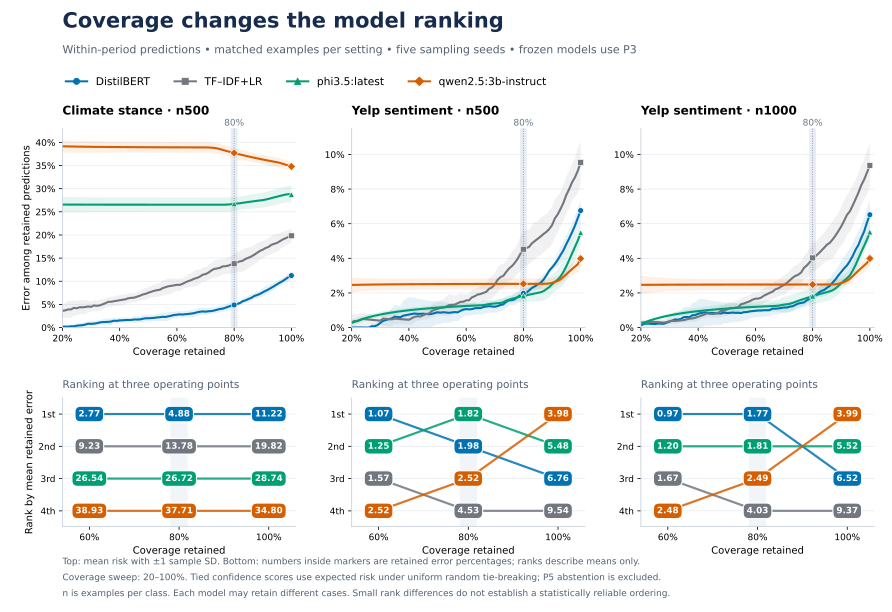

**Generated text:** `RQ2_results.tex`, `RQ2_discussion.tex`, and `RQ2_selective_methods.tex`. **Tables:** `RQ2_Table9.tex` and `RQ2_temporal_reliability_table.tex`. The figure fragment in `RQ2_coverage_figure.tex` uses the generated PDF; place it in the same LaTeX directory. The `booktabs` and `graphicx` packages are required.

In [10]:
from IPython.display import display, SVG, Markdown

display(SVG(filename=str(OUT_DIR / "RQ2_coverage_rankings.svg")))
display(Markdown("**Generated text:** `RQ2_results.tex`, `RQ2_discussion.tex`, and `RQ2_selective_methods.tex`. "
                 "**Tables:** `RQ2_Table9.tex` and `RQ2_temporal_reliability_table.tex`. "
                 "The figure fragment in `RQ2_coverage_figure.tex` uses the generated PDF; "
                 "place it in the same LaTeX directory. The `booktabs` and `graphicx` packages are required."))
